In [1]:
MODEL_NAME = 'aubmindlab/aragpt2-base'
MIN_SCORE = 6
BLOCK_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 4
LR = 5e-5
WARMUP_RATIO = 0.06
WEIGHT_DECAY = 0.01
SEED = 42
OUT_DIR = '/kaggle/working/aragpt2-economy-ar'

In [2]:
import glob, json, math, os, random, re, time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'
print('torch', torch.__version__, '| transformers', transformers.__version__)
print('device:', torch.cuda.get_device_name(0) if USE_AMP else 'CPU  <-- turn on the GPU: Settings > Accelerator')

torch 2.11.0+cu130 | transformers 5.20.2
device: Tesla T4


In [3]:
candidates = sorted(glob.glob('/kaggle/input/**/*.csv', recursive=True),
                    key=lambda p: os.path.basename(p) != 'dataset.csv')
assert candidates, 'No CSV in /kaggle/input: upload Part1/data/dataset.csv with Add Input > Upload, then run again.'
DATA_FILE = candidates[0]
raw = pd.read_csv(DATA_FILE)
print('file:', DATA_FILE, '| shape', raw.shape)

if 'Score' in raw.columns:
    if 'section' in raw.columns:
        display(raw.groupby('section').Score.describe().round(2))
    raw = raw[raw.Score >= MIN_SCORE]
df = raw.rename(columns={'Text': 'text'})
df = df[[c for c in ('text', 'url') if c in df.columns]].dropna(subset=['text']).reset_index(drop=True)
print(len(df), f'passages kept (score >= {MIN_SCORE})')

file: /kaggle/input/datasets/moussamouhandomar/dataset/dataset.csv | shape (7109, 8)


,count,mean,std,min,25%,50%,75%,max
section,,,,,,,,
culture,1320.0,2.16,1.60,0.0,1.0,2.0,3.0,8.5
economy,3918.0,7.19,1.72,1.0,6.0,7.5,8.5,10.0
society,1134.0,3.64,1.96,0.0,2.0,3.5,5.0,10.0
sport,737.0,2.18,1.77,0.0,1.0,2.0,3.0,9.0


3453 passages kept (score >= 6)


In [4]:
DIACRITICS = re.compile('[' + chr(0x0617) + '-' + chr(0x061A) + chr(0x064B) + '-' + chr(0x0652)
                        + chr(0x0670) + chr(0x0640) + ']')

def clean(t):
    t = re.sub(r'https?://\S+', ' ', str(t))
    t = DIACRITICS.sub('', t)
    t = re.sub(r'[ \t]+', ' ', t)
    return re.sub(r'\n\s*', '\n', t).strip()

df['text'] = df['text'].map(clean)
df = df[df.text.str.split().str.len() >= 30].drop_duplicates('text').reset_index(drop=True)
df['words'] = df.text.str.split().str.len()
display(df.words.describe().round(1).to_frame('words per passage').T)

groups = df['url'] if 'url' in df.columns else pd.Series(range(len(df)))
articles = groups.unique()
np.random.RandomState(SEED).shuffle(articles)
is_val = groups.isin(set(articles[: max(1, int(0.1 * len(articles)))]))
val_texts = df.text[is_val].tolist()
train_texts = df.text[~is_val].tolist()
print(f'{len(articles)} articles | train {len(train_texts)} passages | val {len(val_texts)} passages | '
      f'{df.words.sum():,} words in total')
print('\nexample:\n', df.text.iloc[0][:500])

,count,mean,std,min,25%,50%,75%,max
words per passage,3453.0,61.5,15.2,40.0,49.0,59.0,70.0,155.0


505 articles | train 3108 passages | val 345 passages | 212,353 words in total

example:
 قضت المحكمة الابتدائية التجارية بالدار البيضاء بثبوت التزييف في حق شركة مغربية تستورد وتعرض منتجات تحمل علامات تجارية مملوكة للاتحاد الدولي لكرة القدم “فيفا”، من بينها علامة الاتحاد ورسم كأس العالم. وأمرت المحكمة الشركة، وفق منطوق الحكم، بالتوقف عن استيراد وعرض وبيع جميع المنتجات الحاملة لعلامات مزيفة مملوكة ل”فيفا”، تحت طائلة غرامة تهديدية قدرها 5 آلاف درهم عن كل مخالفة تتم معاينتها بعد تبليغ الحكم وصيرورته نهائيا.


In [5]:
from transformers import AutoModelForCausalLM, AutoTokenizer, get_linear_schedule_with_warmup

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)
print(f'{MODEL_NAME}: {type(model).__name__}, {sum(p.numel() for p in model.parameters()) / 1e6:.0f} M parameters, '
      f'vocab {len(tokenizer):,}, context {model.config.n_positions}')
sample = 'ارتفعت أسعار المحروقات في الأسواق المغربية'
print(len(tokenizer.tokenize(sample)), 'tokens:', tokenizer.tokenize(sample))

aubmindlab/aragpt2-base: GPT2LMHeadModel, 135 M parameters, vocab 64,000, context 1024
7 tokens: ['Ø§Ø±Øª', 'ÙģØ¹Øª', 'ĠØ£Ø³Ø¹Ø§Ø±', 'ĠØ§ÙĦÙħØŃØ±ÙĪÙĤØ§Øª', 'ĠÙģÙĬ', 'ĠØ§ÙĦØ£Ø³ÙĪØ§ÙĤ', 'ĠØ§ÙĦÙħØºØ±Ø¨ÙĬØ©']


In [6]:
def to_blocks(texts):
    ids = []
    for enc in tokenizer(texts, add_special_tokens=False).input_ids:
        ids += enc + [tokenizer.eos_token_id]
    n = len(ids) // BLOCK_SIZE
    return torch.tensor(ids[: n * BLOCK_SIZE]).view(n, BLOCK_SIZE), len(ids)

train_blocks, n_train_tok = to_blocks(train_texts)
val_blocks, n_val_tok = to_blocks(val_texts)
print(f'train: {n_train_tok:,} tokens -> {len(train_blocks)} blocks | val: {n_val_tok:,} tokens -> {len(val_blocks)} blocks')

train_loader = torch.utils.data.DataLoader(train_blocks, batch_size=BATCH_SIZE, shuffle=True,
                                           generator=torch.Generator().manual_seed(SEED))
val_loader = torch.utils.data.DataLoader(val_blocks, batch_size=BATCH_SIZE)

train: 268,881 tokens -> 1050 blocks | val: 30,089 tokens -> 117 blocks


In [7]:
@torch.no_grad()
def evaluate(loader):
    model.eval()
    total, n = 0.0, 0
    for x in loader:
        x = x.to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            loss = model(input_ids=x, labels=x).loss
        total += loss.item() * x.size(0)
        n += x.size(0)
    return total / n

SAMPLING = dict(do_sample=True, top_k=50, top_p=0.95, temperature=0.8)

@torch.no_grad()
def generate(prompt, max_new_tokens=120, seed=SEED, **kwargs):
    model.eval()
    set_seed(seed)
    enc = tokenizer(prompt, return_tensors='pt').to(device)
    params = {**SAMPLING, **kwargs} if kwargs.get('do_sample', True) else dict(kwargs)
    params.setdefault('repetition_penalty', 1.2)
    params.setdefault('no_repeat_ngram_size', 3)
    out = model.generate(**enc, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.eos_token_id, **params)
    return tokenizer.decode(out[0], skip_special_tokens=True)

PROMPTS = [
    'ارتفعت أسعار المحروقات في المغرب',
    'أعلن بنك المغرب أن معدل التضخم',
    'سجلت بورصة الدار البيضاء',
    'تسعى الحكومة إلى جذب الاستثمارات الأجنبية',
    'يعاني الفلاحون من ارتفاع تكاليف الإنتاج',
]

In [8]:
val_loss_before = evaluate(val_loader)
print(f'BEFORE fine-tuning: val loss {val_loss_before:.3f} | perplexity {math.exp(val_loss_before):.1f}\n')
before = {p: generate(p) for p in PROMPTS}
for t in before.values():
    print('>>', t, '\n')

BEFORE fine-tuning: val loss 4.673 | perplexity 107.1

>> ارتفعت أسعار المحروقات في المغرب ، السبت 17 يناير كانون الثاني ، إلى أقل مستوياتها منذ 2014 ، فيما سجلت محطات الوقود زيادة كبيرة خلال الشهرين السابقين .وحسب مصادر من الاتحاد المغربي للشغل فإن الزيادة في الأسعار ستكون نتيجة طبيعية للارتفاع الكبير الذي سجلته اسعار النفط التي ارتفعت الى حوالي 100 دولار للبرميل الواحد خلال الأسابيع الماضية .وأوردت المصادر أن سعر بيع برميل البترول بلغ نحو 40 دولارا في الأسبوع الأول من الشهر الحالي ، بعد الارتفاع المسجل في الأسواق العالمية على مدى الأشهر الستة الأخيرة .ونقلت صحيفة " الأخبار " عن مصدر مقرب من حزب العدالة والتنمية قوله إن ارتفاع أسعار الخام يعود جزئيا لانهيار المخزونات الأميركية وتراجع الطلب بفعل هبوط حاد في الإنتاج 

>> أعلن بنك المغرب أن معدل التضخم انتقل إلى 9 , 13 في المائة ، محققا بذلك ارتفاعا طفيفا عن مستوى 10 , 3 في المائة الذي سجلته نهاية شهر نونبر 2016 .وأوضح البنك المركزي المغربي في تقرير له بعنوان " مؤشر أسعار المستهلكين لسنة 2018 ، أنه ارتفع بنسبة 1 , 2 % مقارنة مع نفس الفتر

In [9]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

history, step_losses, best_val = [], [], float('inf')
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    for i, x in enumerate(train_loader, 1):
        x = x.to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            loss = model(input_ids=x, labels=x).loss
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        running += loss.item()
        step_losses.append(loss.item())
        if i % 50 == 0:
            print(f'  epoch {epoch} step {i}/{len(train_loader)} loss {running / i:.3f}')
    train_loss, val_loss = running / len(train_loader), evaluate(val_loader)
    minutes = (time.time() - t0) / 60
    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
                    'val_ppl': math.exp(val_loss), 'minutes': minutes})
    print(f'epoch {epoch}: train {train_loss:.3f} | val {val_loss:.3f} | ppl {math.exp(val_loss):.1f} | {minutes:.1f} min')
    if val_loss < best_val:
        best_val = val_loss
        model.save_pretrained(OUT_DIR)
        tokenizer.save_pretrained(OUT_DIR)
        print('  -> best model saved')

  epoch 1 step 50/132 loss 6.853
  epoch 1 step 100/132 loss 5.864
epoch 1: train 5.556 | val 3.816 | ppl 45.4 | 0.5 min
  -> best model saved
  epoch 2 step 50/132 loss 4.288
  epoch 2 step 100/132 loss 4.262
epoch 2: train 4.228 | val 3.633 | ppl 37.8 | 1.1 min
  -> best model saved
  epoch 3 step 50/132 loss 3.999
  epoch 3 step 100/132 loss 3.966
epoch 3: train 3.952 | val 3.563 | ppl 35.3 | 1.6 min
  -> best model saved
  epoch 4 step 50/132 loss 3.833
  epoch 4 step 100/132 loss 3.837
epoch 4: train 3.821 | val 3.549 | ppl 34.8 | 2.2 min
  -> best model saved


,epoch,train_loss,val_loss,val_ppl,minutes
0,1,5.556,3.816,45.404,0.526
1,2,4.228,3.633,37.843,1.070
2,3,3.952,3.563,35.270,1.621
3,4,3.821,3.549,34.775,2.181


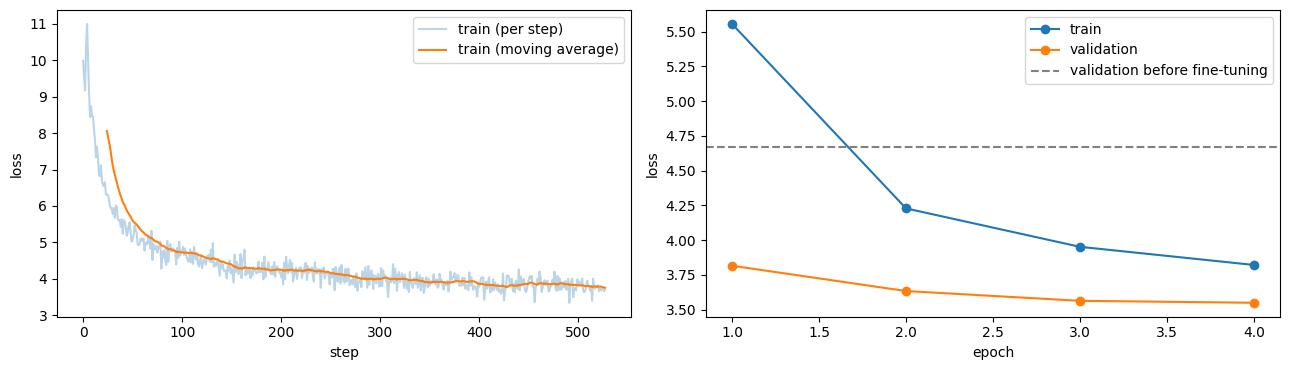

In [10]:
model = AutoModelForCausalLM.from_pretrained(OUT_DIR).to(device)
hist = pd.DataFrame(history)
display(hist.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(step_losses, alpha=0.3, label='train (per step)')
ax[0].plot(pd.Series(step_losses).rolling(25).mean(), label='train (moving average)')
ax[0].set_xlabel('step'); ax[0].set_ylabel('loss'); ax[0].legend()
ax[1].plot(hist.epoch, hist.train_loss, 'o-', label='train')
ax[1].plot(hist.epoch, hist.val_loss, 'o-', label='validation')
ax[1].axhline(val_loss_before, ls='--', c='gray', label='validation before fine-tuning')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('loss'); ax[1].legend()
plt.tight_layout(); plt.savefig('/kaggle/working/loss_curves.png', dpi=120); plt.show()

In [11]:
after = {p: generate(p) for p in PROMPTS}
pd.DataFrame({'prompt': PROMPTS,
              'before fine-tuning': [before[p] for p in PROMPTS],
              'after fine-tuning': [after[p] for p in PROMPTS]}).to_csv('/kaggle/working/generations.csv', index=False)
for p in PROMPTS:
    print('PROMPT :', p)
    print('BEFORE :', before[p])
    print('AFTER  :', after[p])
    print('-' * 100)

PROMPT : ارتفعت أسعار المحروقات في المغرب
BEFORE : ارتفعت أسعار المحروقات في المغرب ، السبت 17 يناير كانون الثاني ، إلى أقل مستوياتها منذ 2014 ، فيما سجلت محطات الوقود زيادة كبيرة خلال الشهرين السابقين .وحسب مصادر من الاتحاد المغربي للشغل فإن الزيادة في الأسعار ستكون نتيجة طبيعية للارتفاع الكبير الذي سجلته اسعار النفط التي ارتفعت الى حوالي 100 دولار للبرميل الواحد خلال الأسابيع الماضية .وأوردت المصادر أن سعر بيع برميل البترول بلغ نحو 40 دولارا في الأسبوع الأول من الشهر الحالي ، بعد الارتفاع المسجل في الأسواق العالمية على مدى الأشهر الستة الأخيرة .ونقلت صحيفة " الأخبار " عن مصدر مقرب من حزب العدالة والتنمية قوله إن ارتفاع أسعار الخام يعود جزئيا لانهيار المخزونات الأميركية وتراجع الطلب بفعل هبوط حاد في الإنتاج
AFTER  : ارتفعت أسعار المحروقات في المغرب بأكثر من 17,6 مليار درهم، مقابل ارتفاع الكميات المستوردة بنسبة 10,9 مليارات درهم خلال الفترة نفسها من السنة الماضية.
----------------------------------------------------------------------------------------------------
PROMPT : أعلن بنك المغ

In [12]:
prompt = 'قال وزير الاقتصاد والمالية إن'
strategies = {
    'greedy': dict(do_sample=False),
    'beam search (5 beams)': dict(do_sample=False, num_beams=5),
    'top-k sampling (k=50)': dict(top_k=50, top_p=1.0),
    'nucleus sampling (p=0.92, T=0.7)': dict(top_k=0, top_p=0.92, temperature=0.7),
}
decoding = {name: generate(prompt, max_new_tokens=100, **kw) for name, kw in strategies.items()}
for name, text in decoding.items():
    print(f'[{name}]\n{text}\n')

[greedy]
قال وزير الاقتصاد والمالية إن “أما بالنسبة إلى المقاولات الصغيرة والمتوسطة، فإن هذا الوضع لا يعني بالضرورة أن يكون مرتبطا بحجم الاستثمارات التي يمكن تخصيصها في القطاع الخاص.

[beam search (5 beams)]
قال وزير الاقتصاد والمالية إن ارتفاع أسعار النفط إلى مستويات قياسية خلال الأشهر التسعة الأولى من السنة الجارية، ساهم في تقليص عجز الميزانية العامة بنسبة 3,5 في المائة، رغم استمرار المخاوف بشأن قدرة الاقتصاد على امتصاص الصدمات الخارجية.

[top-k sampling (k=50)]
قال وزير الاقتصاد والمالية إن “في سياق حديث عن زيادة الرواتب، قال علي أن الزيادة المرتقبة خلال سنة 2026 ستكون مرتبطة أساسا بتحسين القدرة الشرائية للمواطنين.

[nucleus sampling (p=0.92, T=0.7)]
قال وزير الاقتصاد والمالية إن “في سياق حديث عن آفاق نمو مستدام، فإن الحكومة تعمل على تقليص العجز إلى 4,4 في المائة خلال سنة 2025؛ ما يعكس تحسنا واضحا في توقعات النمو الاقتصادي.



In [13]:
my_sentence = 'تراجعت قيمة الدرهم أمام الدولار'
print(generate(my_sentence, max_new_tokens=150))

تراجعت قيمة الدرهم أمام الدولار، بعدما تراجع إلى 1,25 في المائة بنهاية غشت الماضي.


In [14]:
summary = {
    'model': MODEL_NAME,
    'gpu': torch.cuda.get_device_name(0) if USE_AMP else 'cpu',
    'data_file': DATA_FILE, 'min_score': MIN_SCORE,
    'articles': len(articles), 'passages': len(df), 'train_passages': len(train_texts), 'val_passages': len(val_texts),
    'train_tokens': n_train_tok, 'val_tokens': n_val_tok,
    'train_blocks': len(train_blocks), 'val_blocks': len(val_blocks),
    'config': dict(BLOCK_SIZE=BLOCK_SIZE, BATCH_SIZE=BATCH_SIZE, EPOCHS=EPOCHS, LR=LR,
                   WARMUP_RATIO=WARMUP_RATIO, WEIGHT_DECAY=WEIGHT_DECAY),
    'val_loss_before': round(val_loss_before, 4), 'val_ppl_before': round(math.exp(val_loss_before), 2),
    'best_val_loss': round(best_val, 4), 'best_val_ppl': round(math.exp(best_val), 2),
    'history': [{k: round(v, 4) for k, v in h.items()} for h in history],
}
with open('/kaggle/working/summary.json', 'w', encoding='utf-8') as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print(json.dumps(summary, ensure_ascii=False, indent=2))

{
  "model": "aubmindlab/aragpt2-base",
  "gpu": "Tesla T4",
  "data_file": "/kaggle/input/datasets/moussamouhandomar/dataset/dataset.csv",
  "min_score": 6,
  "articles": 505,
  "passages": 3453,
  "train_passages": 3108,
  "val_passages": 345,
  "train_tokens": 268881,
  "val_tokens": 30089,
  "train_blocks": 1050,
  "val_blocks": 117,
  "config": {
    "BLOCK_SIZE": 256,
    "BATCH_SIZE": 8,
    "EPOCHS": 4,
    "LR": 5e-05,
    "WARMUP_RATIO": 0.06,
    "WEIGHT_DECAY": 0.01
  },
  "val_loss_before": 4.6733,
  "val_ppl_before": 107.05,
  "best_val_loss": 3.5489,
  "best_val_ppl": 34.78,
  "history": [
    {
      "epoch": 1,
      "train_loss": 5.5562,
      "val_loss": 3.8156,
      "val_ppl": 45.4038,
      "minutes": 0.5263
    },
    {
      "epoch": 2,
      "train_loss": 4.2284,
      "val_loss": 3.6334,
      "val_ppl": 37.8428,
      "minutes": 1.0696
    },
    {
      "epoch": 3,
      "train_loss": 3.9518,
      "val_loss": 3.563,
      "val_ppl": 35.2697,
      "minutes"